In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

print("PhysicsLab Analyzer")
print("All libraries loaded successfully!")

PhysicsLab Analyzer
All libraries loaded successfully!


In [ ]:
# Hooke's Law Experiment
# F = kx

import numpy as np
import pandas as pd

# Sample experimental data
extension = np.array ([0.01, 0.02, 0.03, 0.04, 0.05])
force = np.array([0.52, 0.98, 1.51, 2.03, 2.48])

# Create data table
data = pd.DataFrame({
    "Extension (m)": extension, "Force (N)": force})

print("Hooke's Law Experimental Data")
print(data)

# Calculate spring constant
k = np.polyfit(extension, force, 1)[0]

print(f"\nSpring Constant = {k:.2f} N/m'' ")

Hooke's Law Experimental Data
   Extension (m)  Force (N)
0           0.01       0.52
1           0.02       0.98
2           0.03       1.51
3           0.04       2.03
4           0.05       2.48

Spring Constant = 49.70 N/m'' 


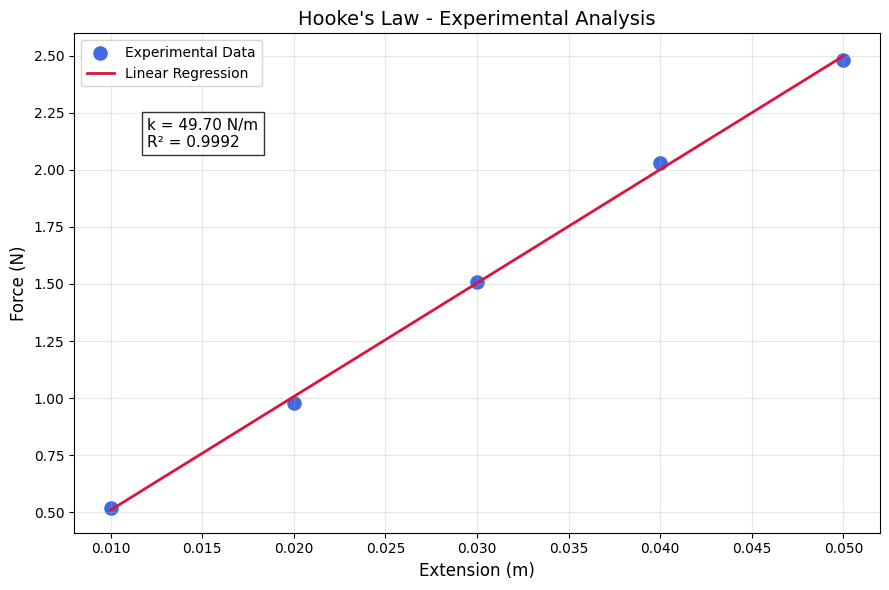

Spring Constant: 49.70 N/m
R-squared: 0.9992


In [ ]:


# PhysicsLab Analyzer - Data Visualization

import matplotlib.pyplot as plt
import numpy as np

# Linear regression
slope, intercept = np.polyfit(extension, force, 1)

# Predicted values
predicted_force = slope * extension + intercept

# Calculate R-squared
ss_res = np.sum((force - predicted_force)**2)
ss_tot = np.sum((force - np.mean(force))**2)
r_squared = 1 - (ss_res / ss_tot)

# Create graph
plt.figure(figsize=(9, 6))

plt.scatter(
    extension, force,
    color="royalblue",
    s=90,
    label="Experimental Data"
)

plt.plot(
    extension, predicted_force,
    color="crimson",
    linewidth=2,
    label="Linear Regression"
)

plt.xlabel("Extension (m)", fontsize=12)
plt.ylabel("Force (N)", fontsize=12)
plt.title("Hooke's Law - Experimental Analysis", fontsize=14)

plt.text(
    0.012, 2.1,
    f"k = {slope:.2f} N/m\nR² = {r_squared:.4f}",
    fontsize=11,
    bbox=dict(facecolor="white", alpha=0.8)
)

plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(f"Spring Constant: {slope:.2f} N/m")
print(f"R-squared: {r_squared:.4f}")


In [ ]:

# Uncertainty Analysis

from scipy.stats import linregress

result = linregress(extension, force)

k = result.slope
k_uncertainty = result.stderr

print("=== Uncertainty Analysis ===")
print(f"Spring Constant: {k:.2f} N/m")
print(f"Standard Error: {k_uncertainty:.2f} N/m")
print(f"R-squared: {result.rvalue**2:.4f}")

print(
    f"\nFinal Result: "
    f"k = ({k:.2f} ± {k_uncertainty:.2f}) N/m"
)


=== Uncertainty Analysis ===
Spring Constant: 49.70 N/m
Standard Error: 0.82 N/m
R-squared: 0.9992

Final Result: k = (49.70 ± 0.82) N/m


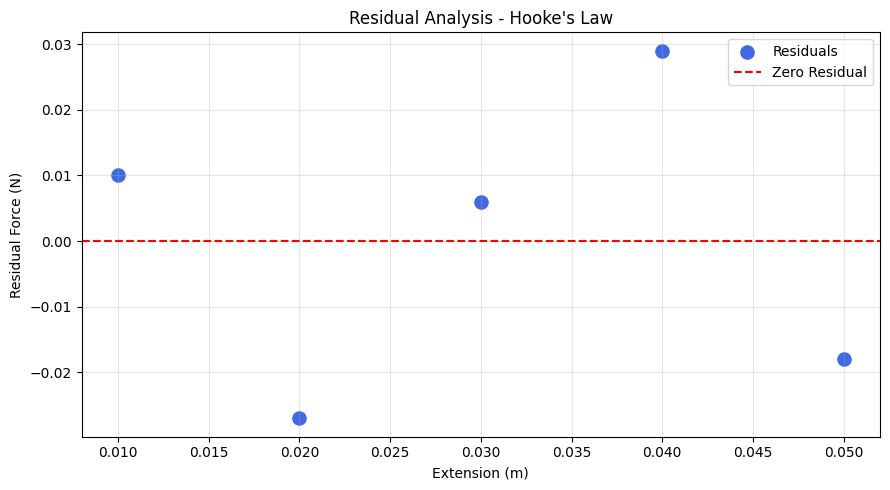

RMSE: 0.0201 N
Residual Analysis Completed!


In [ ]:

# PhysicsLab Analyzer - Residual Analysis

import numpy as np
import matplotlib.pyplot as plt

# Calculate predicted force
predicted = result.slope * extension + result.intercept

# Calculate residuals
residuals = force - predicted

# Plot residuals
plt.figure(figsize=(9, 5))

plt.scatter(
    extension,
    residuals,
    color="royalblue",
    s=90,
    label="Residuals"
)

plt.axhline(
    y=0,
    color="red",
    linestyle="--",
    label="Zero Residual"
)

plt.xlabel("Extension (m)")
plt.ylabel("Residual Force (N)")
plt.title("Residual Analysis - Hooke's Law")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# Root Mean Squared Error
rmse = np.sqrt(np.mean(residuals**2))

print(f"RMSE: {rmse:.4f} N")
print("Residual Analysis Completed!")


In [9]:

# PhysicsLab Analyzer - File Upload

import pandas as pd
from google.colab import files
from io import BytesIO

print("Upload your experimental data file")

uploaded = files.upload()

if uploaded:
    filename = next(iter(uploaded))
    file_content = BytesIO(uploaded[filename])

    if filename.lower().endswith(".csv"):
        df = pd.read_csv(file_content)
    elif filename.lower().endswith((".xlsx", ".xls")):
        df = pd.read_excel(file_content)
    else:
        raise ValueError("Please upload a CSV or Excel file.")

    print("\nFile uploaded successfully!")
    print("Dataset shape:", df.shape)
    display(df.head())
    print("\nAvailable columns:")
    print(df.columns.tolist())


Upload your experimental data file


Saving hookes_law_data.csv to hookes_law_data (1).csv

File uploaded successfully!
Dataset shape: (5, 2)


,Extension (m),Force (N)
0,0.01,0.52
1,0.02,0.98
2,0.03,1.51
3,0.04,2.03
4,0.05,2.48



Available columns:
['Extension (m)', 'Force (N)']


In [8]:

import pandas as pd
from google.colab import files

sample = pd.DataFrame({
    "Extension (m)": [0.01, 0.02, 0.03, 0.04, 0.05],
    "Force (N)": [0.52, 0.98, 1.51, 2.03, 2.48]
})

sample.to_csv("hookes_law_data.csv", index=False)
files.download("hookes_law_data.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

=== PhysicsLab Analysis ===
X-axis: Extension (m)
Y-axis: Force (N)
Slope: 49.7000
Intercept: 0.0130
R-squared: 0.9992
Slope Standard Error: 0.8226
RMSE: 0.0201


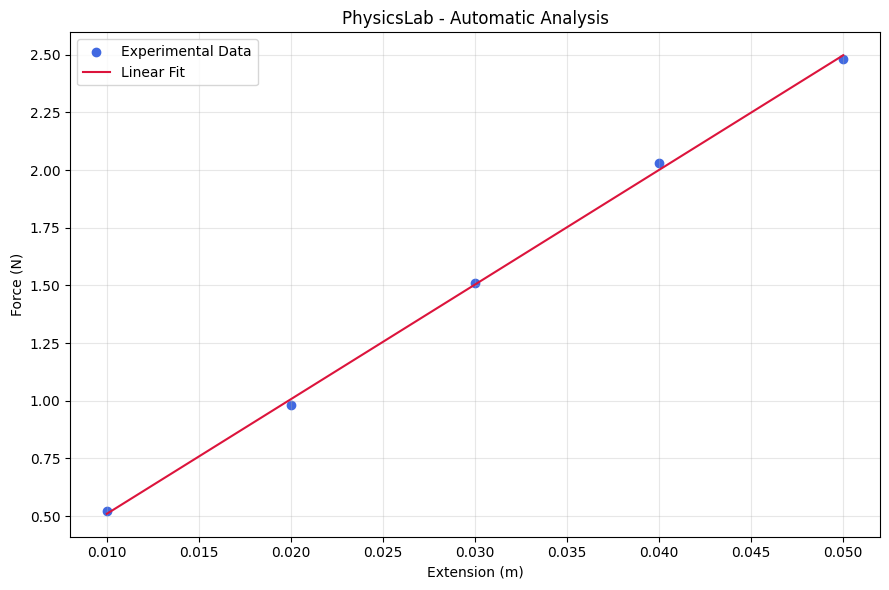

In [10]:

# PhysicsLab Analyzer
# Automatic Data Analysis

import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import linregress

# Select columns from uploaded file
x_column = df.columns[0]
y_column = df.columns[1]

# Convert data to numeric values
data_clean = df[[x_column, y_column]].copy()

for col in [x_column, y_column]:
    data_clean[col] = pd.to_numeric(
        data_clean[col], errors="coerce"
    )

data_clean = data_clean.dropna()

if len(data_clean) < 3:
    raise ValueError("At least 3 valid data points are required.")

x = data_clean[x_column].to_numpy()
y = data_clean[y_column].to_numpy()

if np.unique(x).size < 2:
    raise ValueError("X values must not all be identical.")

# Perform linear regression
fit = linregress(x, y)
predicted = fit.slope * x + fit.intercept

# Calculate errors
residuals = y - predicted
rmse = np.sqrt(np.mean(residuals**2))

# Display results
print("=== PhysicsLab Analysis ===")
print(f"X-axis: {x_column}")
print(f"Y-axis: {y_column}")
print(f"Slope: {fit.slope:.4f}")
print(f"Intercept: {fit.intercept:.4f}")
print(f"R-squared: {fit.rvalue**2:.4f}")
print(f"Slope Standard Error: {fit.stderr:.4f}")
print(f"RMSE: {rmse:.4f}")

# Plot results
x_line = np.linspace(x.min(), x.max(), 100)
y_line = fit.slope * x_line + fit.intercept

plt.figure(figsize=(9, 6))
plt.scatter(x, y, color="royalblue",
            label="Experimental Data")
plt.plot(x_line, y_line, color="crimson",
         label="Linear Fit")

plt.xlabel(x_column)
plt.ylabel(y_column)
plt.title("PhysicsLab - Automatic Analysis")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [11]:

# PhysicsLab Analyzer - PDF Report

import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages
from google.colab import files

report_name = "PhysicsLab_Report.pdf"

with PdfPages(report_name) as pdf:

    # Page 1: Analysis results
    fig, ax = plt.subplots(figsize=(8.27, 11.69))
    ax.axis("off")

    report = (
        "PhysicsLab Analyzer\n"
        "Experimental Data Analysis Report\n\n"
        f"X-axis: {x_column}\n"
        f"Y-axis: {y_column}\n\n"
        f"Number of measurements: {len(x)}\n"
        f"Slope: {fit.slope:.4f}\n"
        f"Intercept: {fit.intercept:.4f}\n"
        f"R-squared: {fit.rvalue**2:.4f}\n"
        f"Slope Standard Error: {fit.stderr:.4f}\n"
        f"RMSE: {rmse:.4f}\n\n"
        "Model: y = slope * x + intercept\n"
        "Note: Results assume a linear model.\n"
        "Standard error excludes instrument uncertainty."
    )

    ax.text(
        0.08, 0.92, report,
        transform=ax.transAxes,
        fontsize=13,
        va="top",
        linespacing=1.7
    )

    pdf.savefig(fig)
    plt.close(fig)

    # Page 2: Graph
    fig, ax = plt.subplots(figsize=(9, 6))

    ax.scatter(x, y, label="Experimental Data")
    ax.plot(x_line, y_line, label="Linear Fit")

    ax.set_xlabel(x_column)
    ax.set_ylabel(y_column)
    ax.set_title("Experimental Data and Linear Fit")
    ax.legend()
    ax.grid(alpha=0.3)

    pdf.savefig(fig, bbox_inches="tight")
    plt.close(fig)

print("PDF report generated successfully!")
files.download(report_name)


PDF report generated successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>